In [5]:
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
resultado = pd.read_csv('resultado_classificacao_patentes.csv', encoding='utf-8', sep=',')

In [3]:
resultado.head()

,Unnamed: 0,publication_number,filing_date,ipc_codes,title,abstract,4-digitos IPC,ISIC,sim_processo,sim_produto,diferenca,classificacao,grupo_referencia
0,0,BR-112020007064-A2,20180620,D04H,folha elástica para artigo absorvente e artigo...,A presente invenção refere-se a folha elástica...,D04H,13,0.490508,0.585174,-0.0947,Inovação de Produto,"13, 171, 172, 18, 58, 592"
1,1,BR-112013006594-B1,20110920,C07D,Composto ciclopropano antagonista de receptor ...,"COMPOSTO, COMPOSIÇÃO FARMACÊUTICA, MÉTODO DE T...",C07D,21,0.179574,0.341748,-0.1622,Inovação de Produto,"19, 20, 21 e 22"
2,2,BR-112021026164-A2,20200625,G07D,Máquina de transação automatizada e cassete pa...,MÁQUINA DE TRANSAÇÃO AUTOMATIZADA E CASSETE PA...,G07D,32,0.318940,0.204251,0.1147,Inovação de Processo,"14, 15, 16, 173, 174, 31, 32"
3,3,BR-112018070089-A2,20170331,H04L,métodos de operação de um dispositivo sem fio ...,são providos sistemas e métodos para relato da...,H04L,26,0.369450,0.273137,0.0963,Inovação de Processo,"26, 27"
4,4,BR-202021008981-U2,20210507,A22C,Equipamento automático para montar espetinhos ...,EQUIPAMENTO AUTOMÁTICO PARA MONTAR ESPETINHOS ...,A22C,10,0.490840,0.377578,0.1133,Inovação de Processo,"10, 11 e 12"


In [4]:
resultado.drop(columns=['Unnamed: 0'], inplace=True)

In [11]:
isic_excluir = [36, 59, 86, 9, 17, 46, 1, 35, 3, 2, 43, 96, 92, 93]

resultado = resultado[
    ~pd.to_numeric(resultado['ISIC'], errors='coerce').isin(isic_excluir)
].copy()

In [13]:
resultado.dropna(inplace=True)

In [22]:
resultado['grupo_referencia'].value_counts()

grupo_referencia
19, 20, 21 e 22                 120026
25, 28, 29, 30                   55115
26, 27                           50524
10, 11 e 12                      26883
23, 24                           23816
14, 15, 16, 173, 174, 31, 32     14107
13, 171, 172, 18, 58, 592        10034
Name: count, dtype: int64

In [20]:
resultado.drop(resultado[resultado['grupo_referencia'] == 'Geral'].index, inplace=True)

In [21]:
resultado.info()

<class 'pandas.DataFrame'>
Index: 300505 entries, 0 to 384324
Data columns (total 12 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   publication_number  300505 non-null  str    
 1   filing_date         300505 non-null  int64  
 2   ipc_codes           300505 non-null  str    
 3   title               300505 non-null  str    
 4   abstract            300505 non-null  str    
 5   4-digitos IPC       300505 non-null  str    
 6   ISIC                300505 non-null  str    
 7   sim_processo        300505 non-null  float64
 8   sim_produto         300505 non-null  float64
 9   diferenca           300505 non-null  float64
 10  classificacao       300505 non-null  str    
 11  grupo_referencia    300505 non-null  str    
dtypes: float64(3), int64(1), str(8)
memory usage: 316.8 MB


<Axes: xlabel='classificacao'>

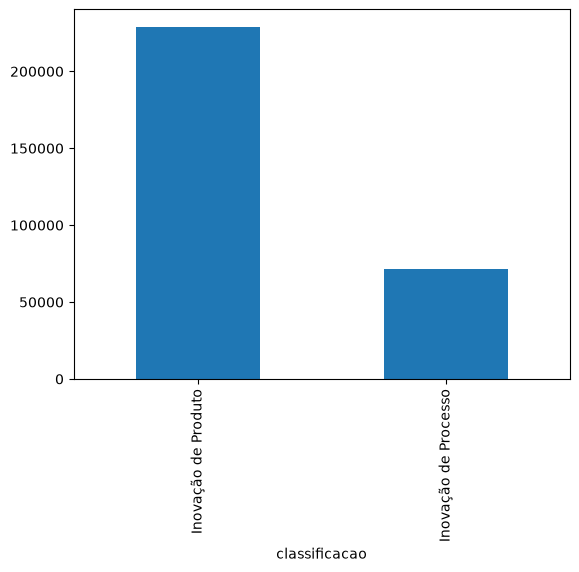

In [23]:
resultado['classificacao'].value_counts().plot(kind='bar')


<Axes: >

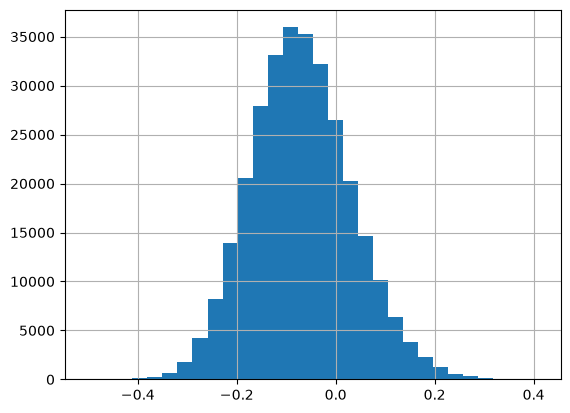

In [29]:
resultado['diferenca'].hist(bins=30)


In [25]:
primeiros100 = resultado.head(100)
primeiros100.to_csv('primeiras100_patentes.csv', index=False, encoding='utf-8')

<Axes: title={'center': 'Média da diferença por classificação'}, xlabel='classificacao'>

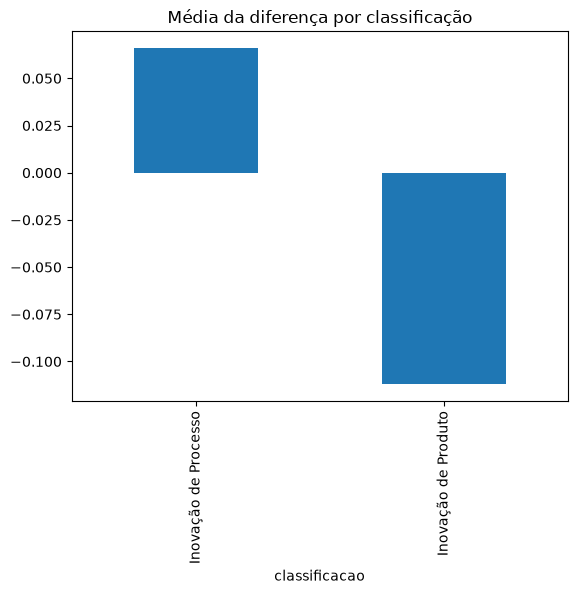

In [28]:
resultado['diferenca'].groupby(resultado['classificacao']).mean().plot(kind='bar', title='Média da diferença por classificação')

<Axes: xlabel='grupo_referencia,classificacao'>

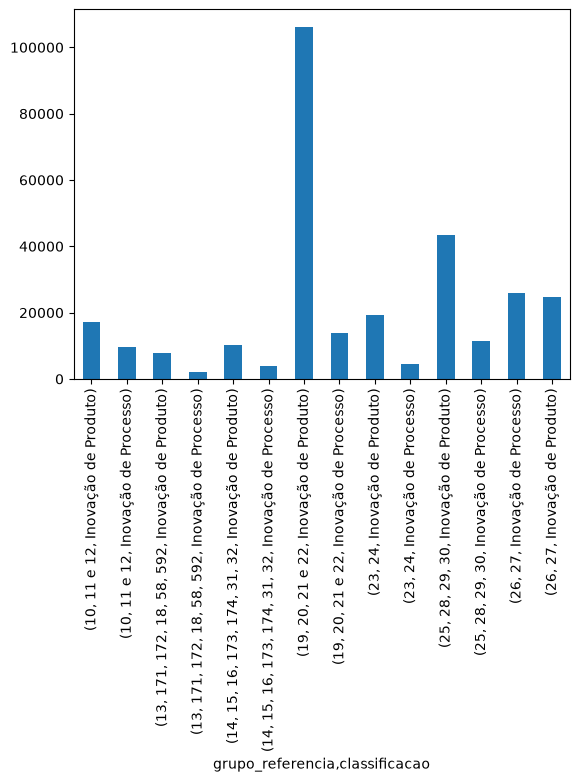

In [35]:
resultado['classificacao'].groupby(resultado['grupo_referencia']).value_counts().plot(kind='bar')

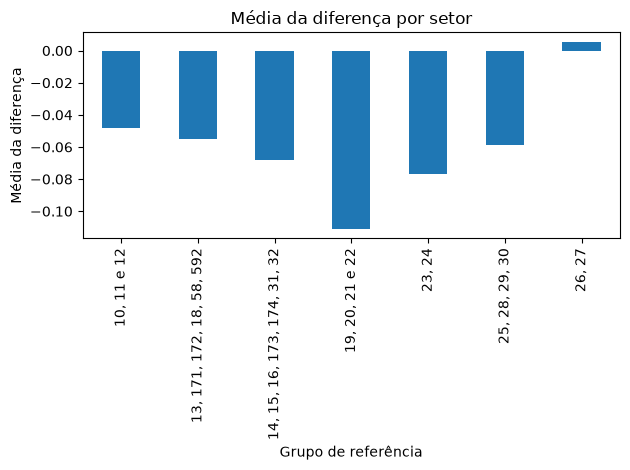

In [33]:
resultado.groupby('grupo_referencia')['diferenca'].mean().plot(
    kind='bar',
    title='Média da diferença por setor'
)

plt.ylabel('Média da diferença')
plt.xlabel('Grupo de referência')
plt.tight_layout()
plt.show()